# 01 · Exploratory Data Analysis & Schema Audit

> **Selection-funnel provenance, survivorship-bias anatomy, and the currency-corruption audit of TMDB 5000.**

Part of the **GreenlightML** pre-release film risk engine. This notebook takes the raw Kaggle dump,
proves the relational merge, quantifies unrecorded financials, isolates currency-scale corruptions,
and defines the **canonical modeling set** handed to the linear baseline in
[`02_baseline_linear_model.ipynb`](./02_baseline_linear_model.ipynb).

**Reproducibility:** run from the repository root (or `notebooks/`) with `python -m nbclient` or
Jupyter Lab. Dataset is fetched by `scripts/download_data.py` or resolved from `../data/`.

## 1. Environment & the 22-Unique-Feature Merge

TMDB 5000 ships as two relationally-linked files: `tmdb_5000_movies.csv` (20 columns) and
`tmdb_5000_credits.csv` (4 columns). Naive concatenation suggests 24 features — but `movie_id`
is a redundant foreign key for `id`, and `title` is duplicated verbatim in both files.
The merge must therefore yield **22 unique features**, not 24.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import get_default_data_paths, load_and_merge_data, filter_clean_theatrical, filter_scale_anomalies

sns.set_theme(style='whitegrid', context='notebook')
mpl.rcParams['figure.dpi'] = 110
mpl.rcParams['axes.titleweight'] = 'bold'
PALETTE = {'flop': '#ef4444', 'success': '#10b981'}

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 150)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

print(f'pandas {pd.__version__} · numpy {np.__version__} · matplotlib {mpl.__version__} · seaborn {sns.__version__}')

movies_path, credits_path = get_default_data_paths()
movies = pd.read_csv(movies_path)
credits = pd.read_csv(credits_path)
print(f'tmdb_5000_movies.csv:  {movies.shape[0]:,} rows × {movies.shape[1]} columns')
print(f'tmdb_5000_credits.csv: {credits.shape[0]:,} rows × {credits.shape[1]} columns')
print(f'Raw column total: {movies.shape[1] + credits.shape[1]} → deduplicated merge must yield {movies.shape[1] + credits.shape[1] - 2} unique features')

df_raw = load_and_merge_data()
assert df_raw.shape[1] == 22, 'Deduplication failed: expected 22 unique features'
print(f'\nMerged dataset: {df_raw.shape[0]:,} titles × {df_raw.shape[1]} unique features '
      '(movie_id key + duplicate title dropped)')
df_raw.head(3)

pandas 3.0.6 · numpy 2.5.4 · matplotlib 3.11.2 · seaborn 0.13.2


tmdb_5000_movies.csv:  4,803 rows × 20 columns
tmdb_5000_credits.csv: 4,803 rows × 4 columns
Raw column total: 24 → deduplicated merge must yield 22 unique features



Merged dataset: 4,803 titles × 22 unique features (movie_id key + duplicate title dropped)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.44,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.00,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.20,11800,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.08,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.00,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.90,4500,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.38,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.00,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.30,4466,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


## 2. Missing & Zero Audit — Selection Funnel, Stage 1

TMDB financials are **community-curated**, and absent values are encoded as `0`, not `NaN`.
A zero budget means "unrecorded production budget"; a zero revenue means "no theatrical gross
ever reported" — typically because the film never secured a theatrical release, or flopped
into distribution oblivion. Both corrupt any profitability label, so they must be pruned.

The auxiliary columns (`tagline`, `homepage`) are marketing-era artifacts — irrelevant for
modeling but useful as audit receipts of the dataset's sparseness.

In [2]:
n_raw = len(df_raw)
zero_budget = int((df_raw['budget'] == 0).sum())
zero_revenue = int((df_raw['revenue'] == 0).sum())
incomplete = int(((df_raw['budget'] == 0) | (df_raw['revenue'] == 0)).sum())

audit_stage1 = pd.DataFrame({
    'Audit metric': [
        'Zero budget (unrecorded production budget)',
        'Zero revenue (no theatrical gross reported)',
        'Incomplete financials (either zero)',
        'Runtime anomalies (NaN or 0 min)',
        'Missing release_date',
        'Missing tagline',
        'Missing homepage',
    ],
    'Count': [
        zero_budget, zero_revenue, incomplete,
        int((df_raw['runtime'].isna() | (df_raw['runtime'] == 0)).sum()),
        int(df_raw['release_date'].isna().sum()),
        int(df_raw['tagline'].isna().sum()),
        int(df_raw['homepage'].isna().sum()),
    ],
})
audit_stage1['Share of raw'] = (audit_stage1['Count'] / n_raw * 100).round(2).map(lambda v: f'{v:.2f}%')
audit_stage1

,Audit metric,Count,Share of raw
0,Zero budget (unrecorded production budget),1037,21.59%
1,Zero revenue (no theatrical gross reported),1427,29.71%
2,Incomplete financials (either zero),1574,32.77%
3,Runtime anomalies (NaN or 0 min),37,0.77%
4,Missing release_date,1,0.02%
5,Missing tagline,844,17.57%
6,Missing homepage,3091,64.36%


In [3]:
df_theatrical = filter_clean_theatrical(df_raw)
print('Stage 1 — theatrical-sample filter (budget > 0 AND revenue > 0):')
print(f'  {n_raw:,} raw titles − {incomplete:,} incomplete ({incomplete / n_raw * 100:.2f}%) = {len(df_theatrical):,} commercially reported films')
print(f'  Status audit inside the theatrical sample: {(df_theatrical["status"] != "Released").sum()} non-Released title(s) retained (has reported gross).')
df_theatrical['status'].value_counts().to_frame('titles')

Stage 1 — theatrical-sample filter (budget > 0 AND revenue > 0):
  4,803 raw titles − 1,574 incomplete (32.77%) = 3,229 commercially reported films
  Status audit inside the theatrical sample: 1 non-Released title(s) retained (has reported gross).


,titles
status,
Released,3228
Post Production,1


**The survivorship trap, quantified:** by pruning unreported films we do not lose a random
sample — we lose the *commercially invisible* ones. What remains is a biased subsample of
films healthy enough to report box office. Section 4 shows this bias is severe: **~75.5%**
of surviving titles grossed more than their nominal budget.

## 3. Currency Scale Corruption — Selection Funnel, Stage 2

A second, subtler corruption class survives Stage 1: **entries recorded without their
million-scale multiplier or with placeholder grosses**. *Rugrats in Paris* carries a $30
"budget"; *Modern Times* (Chaplin, 1936) carries $1; *Chasing Liberty* grossed $12 against
a $23M budget. These are data-entry failures, not economics.

The sanitizing rule is a strict commercial-scale floor: **budget > $10,000 AND revenue > $10,000**
(strict inequality, so boundary records are pruned too). On TMDB 5000 this removes **26 titles**
and leaves the **canonical modeling set**.

In [4]:
df_model = filter_scale_anomalies(df_theatrical)
pruned_idx = df_theatrical.index.difference(df_model.index)
anomaly_table = (
    df_theatrical.loc[pruned_idx, ['title', 'budget', 'revenue', 'release_date']]
    .sort_values('budget')
    .reset_index(drop=True)
)
print('Stage 2 — commercial-scale floor (budget > $10,000 AND revenue > $10,000, strict):')
print(f'  {len(df_theatrical):,} theatrical titles − {len(anomaly_table)} corrupted / below-floor = {len(df_model):,} canonical modeling films')
print(f'\nThe {len(anomaly_table)} pruned titles (sorted by budget):')
anomaly_table

Stage 2 — commercial-scale floor (budget > $10,000 AND revenue > $10,000, strict):
  3,229 theatrical titles − 26 corrupted / below-floor = 3,203 canonical modeling films

The 26 pruned titles (sorted by budget):


,title,budget,revenue,release_date
0,Modern Times,1,8500000,1936-02-05
1,A Farewell to Arms,4,25,1932-12-08
2,Bran Nue Dae,7,7,2009-08-09
3,Split Second,7,5,1992-05-01
4,The Prophecy,8,16,1995-09-01
5,Nurse 3-D,10,10000000,2013-09-28
6,Of Horses and Men,10,11,2013-08-30
7,F.I.S.T.,11,11,1978-04-26
8,Angela's Ashes,25,13,1999-12-25
9,The 51st State,28,14,2001-12-07


**Why strict `>`?** Two boundary titles sit exactly at the $10,000 floor: *Eraserhead*
(budget = $10,000) and *Down Terrace* (revenue = $10,000, a placeholder-style gross for a
film that really earned ~£100k). A strict floor keeps the modeling sample uniformly
above minimum commercial scale — the `$10,000` figure is itself arbitrary; what matters
is that no entry survives with a physically absurd budget/revenue unit scale.

## 4. Target Definitions & the Class Imbalance Receipt

Two profitability definitions will be evaluated in this project:

1. **Didactic target** — `revenue > budget`. Simple break-even; used to expose the dataset's
   structural bias.
2. **Hollywood break-even** — `revenue ≥ 2.0 × budget`. Exhibitors retain roughly half the
   gross, and production budgets exclude Print & Advertising; industry rule-of-thumb places
   real profitability at twice the production budget.

The receipt below shows both, on the Stage-1 audit sample and on the canonical modeling set.

In [5]:
def class_receipt(df: pd.DataFrame) -> pd.Series:
    didactic = df['revenue'] > df['budget']
    hollywood = df['revenue'] >= 2.0 * df['budget']
    return pd.Series({
        'Titles': f'{len(df):,}',
        'Success — revenue > budget': f'{didactic.sum():,} ({didactic.mean() * 100:.2f}%)',
        'Flop — revenue <= budget': f'{(~didactic).sum():,} ({(~didactic).mean() * 100:.2f}%)',
        'Hollywood break-even — >= 2.0×': f'{hollywood.sum():,} ({hollywood.mean() * 100:.2f}%)',
    })

receipt = pd.DataFrame({
    'Stage-1 audit sample': class_receipt(df_theatrical),
    'Canonical modeling set': class_receipt(df_model),
})
receipt.index.name = 'Metric'
receipt

,Stage-1 audit sample,Canonical modeling set
Metric,,
Titles,"3,229","3,203"
Success — revenue > budget,"2,438 (75.50%)","2,428 (75.80%)"
Flop — revenue <= budget,791 (24.50%),775 (24.20%)
Hollywood break-even — >= 2.0×,"1,809 (56.02%)","1,800 (56.20%)"


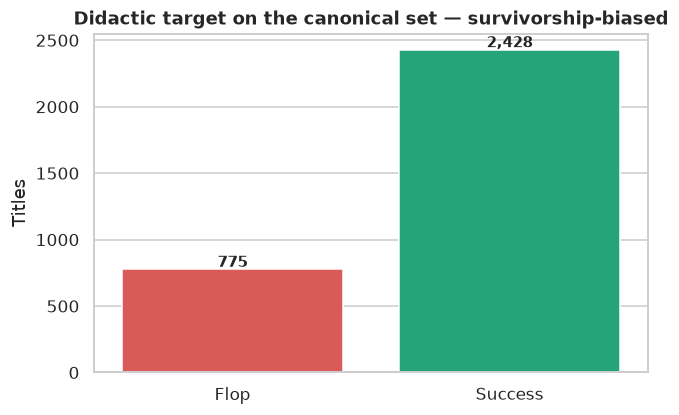

A classifier that blindly predicts "Success" for every title already reaches 75.80% accuracy —
raw accuracy is therefore a vanity metric on this dataset. Modeling stages report Balanced Accuracy, Macro F1 and ROC-AUC.


In [6]:
didactic_counts = df_model['target'].value_counts()
labels = df_model['target'].map({0: 'Flop', 1: 'Success'})

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.countplot(x=labels, hue=labels, order=['Flop', 'Success'], hue_order=['Flop', 'Success'],
              palette={'Flop': PALETTE['flop'], 'Success': PALETTE['success']}, legend=False, ax=ax)
ax.set_title('Didactic target on the canonical set — survivorship-biased')
ax.set_xlabel(''); ax.set_ylabel('Titles')
for i, count in enumerate([didactic_counts.get(0, 0), didactic_counts.get(1, 0)]):
    ax.text(i, count + 20, f'{count:,}', ha='center', fontsize=10, fontweight='bold')
plt.show()

print('A classifier that blindly predicts "Success" for every title already reaches '
      f'{didactic_counts.get(1, 0) / len(df_model) * 100:.2f}% accuracy —')
print('raw accuracy is therefore a vanity metric on this dataset. Modeling stages report Balanced Accuracy, Macro F1 and ROC-AUC.')

## 5. Financial Distributions — the Pareto Concentration

Box office is a winner-take-most market: the mean is dragged by a handful of mega-franchise
outliers while the median tells the true story. Modeling therefore consumes `log1p(budget)`
and treats revenue concentration as a first-class phenomenon.

                      Budget (USD)  Revenue (USD)
Statistic                                        
Mean                 40,953,183.07 122,218,518.82
Median               25,530,000.00  56,308,881.00
Std deviation        44,447,321.46 186,741,253.85
Skewness (raw scale)          2.08           3.81
Skewness (log1p)             -1.10          -1.13

Revenue concentration: top 5 titles = 2.34% of gross · top 20% of titles = 65.6% of gross


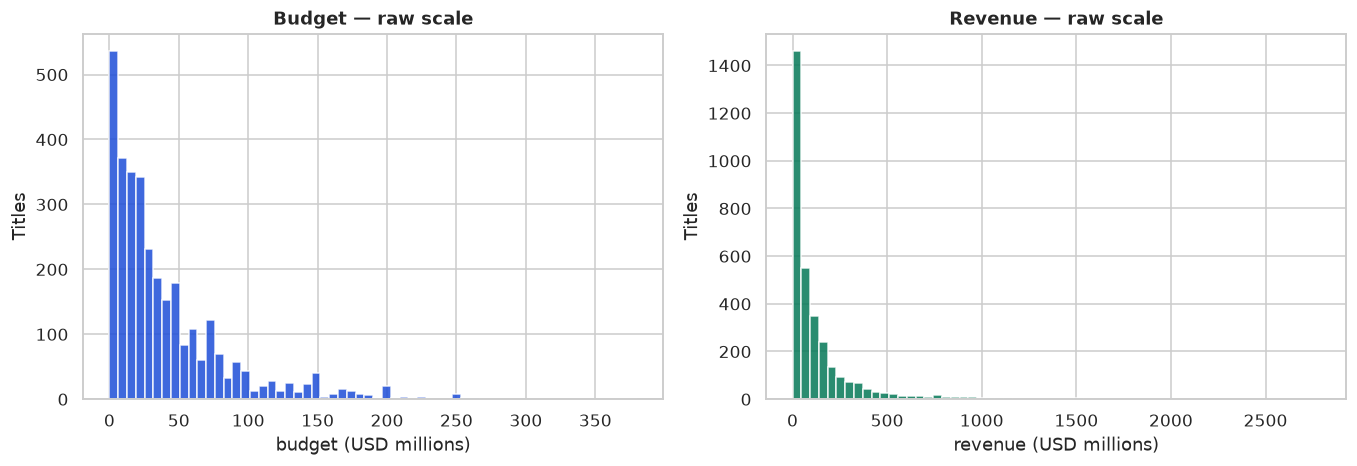

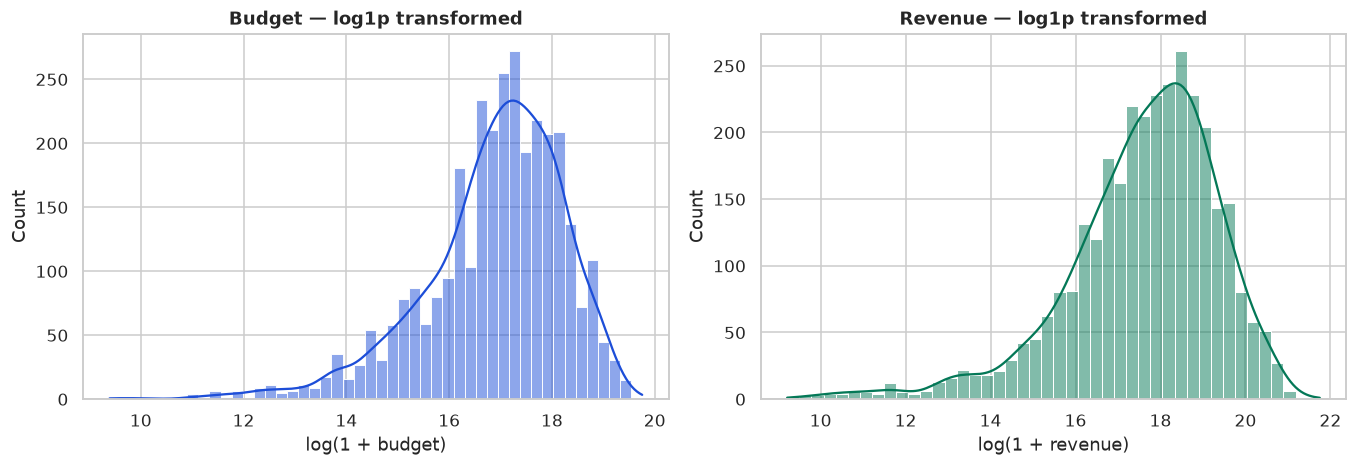

In [7]:
money = df_model[['budget', 'revenue']]
skew_receipt = pd.DataFrame({
    'Statistic': ['Mean', 'Median', 'Std deviation', 'Skewness (raw scale)', 'Skewness (log1p)'],
    'Budget (USD)': [money['budget'].mean(), money['budget'].median(), money['budget'].std(),
                     money['budget'].skew(), np.log1p(money['budget']).skew()],
    'Revenue (USD)': [money['revenue'].mean(), money['revenue'].median(), money['revenue'].std(),
                      money['revenue'].skew(), np.log1p(money['revenue']).skew()],
}).set_index('Statistic')
print(skew_receipt.to_string())

top5_share = df_model.nlargest(5, 'revenue')['revenue'].sum() / df_model['revenue'].sum() * 100
top20pct_share = df_model.nlargest(int(len(df_model) * 0.2), 'revenue')['revenue'].sum() / df_model['revenue'].sum() * 100
print(f'\nRevenue concentration: top 5 titles = {top5_share:.2f}% of gross · top 20% of titles = {top20pct_share:.1f}% of gross')

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, col, color in zip(axes, ['budget', 'revenue'], ['#1d4ed8', '#047857']):
    ax.hist(money[col] / 1e6, bins=60, color=color, alpha=.85)
    ax.set_title(f'{col.capitalize()} — raw scale')
    ax.set_xlabel(f'{col} (USD millions)'); ax.set_ylabel('Titles')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, col, color in zip(axes, ['budget', 'revenue'], ['#1d4ed8', '#047857']):
    sns.histplot(np.log1p(money[col]), kde=True, color=color, ax=ax)
    ax.set_title(f'{col.capitalize()} — log1p transformed')
    ax.set_xlabel(f'log(1 + {col})')
plt.tight_layout(); plt.show()

## 6. Runtime Anatomy

Duration is a clean pre-release signal: fully recorded in the canonical set, mildly
right-tailed, with the theatrical sweet spot around 90–120 minutes.

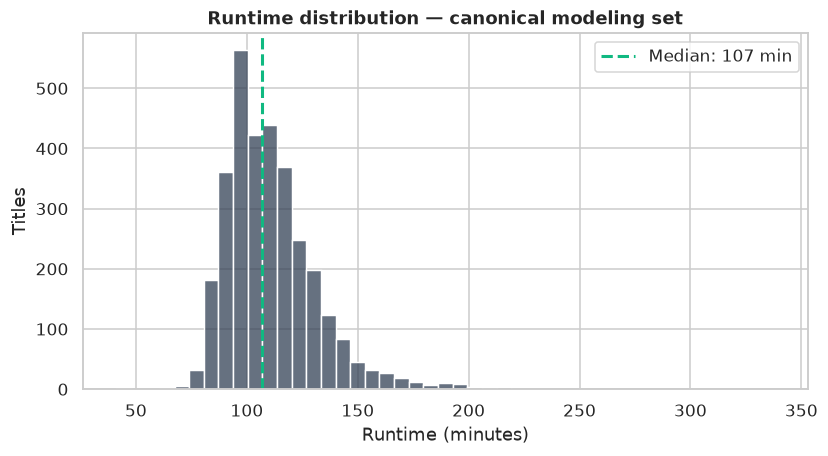

Raw-sample runtime median (audit, > 0 min): 104 min
Canonical-set runtime median: 107 min
Runtime anomalies left in canonical set: NaN = 0, zero = 0


In [8]:
runtime_median_model = df_model['runtime'].median()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.histplot(df_model['runtime'], bins=45, color='#334155', ax=ax)
ax.axvline(runtime_median_model, color='#10b981', lw=2, ls='--', label=f'Median: {runtime_median_model:.0f} min')
ax.set_title('Runtime distribution — canonical modeling set')
ax.set_xlabel('Runtime (minutes)'); ax.set_ylabel('Titles'); ax.legend()
plt.show()

rt_raw = df_raw['runtime'].dropna()
rt_raw = rt_raw[rt_raw > 0]
print(f'Raw-sample runtime median (audit, > 0 min): {rt_raw.median():.0f} min')
print(f'Canonical-set runtime median: {runtime_median_model:.0f} min')
print(f'Runtime anomalies left in canonical set: NaN = {int(df_model["runtime"].isna().sum())}, zero = {int((df_model["runtime"] == 0).sum())}')

## 7. Genre Landscape

Genres arrive as JSON lists; they are the backbone of the pre-release multi-hot block in
the feature store. Drama dominates by count — but count is not commercial weight, which is
why the baseline notebooks encode genres as features rather than filters.

Titles with empty genre lists in canonical set: 1
Distinct genre labels: 19


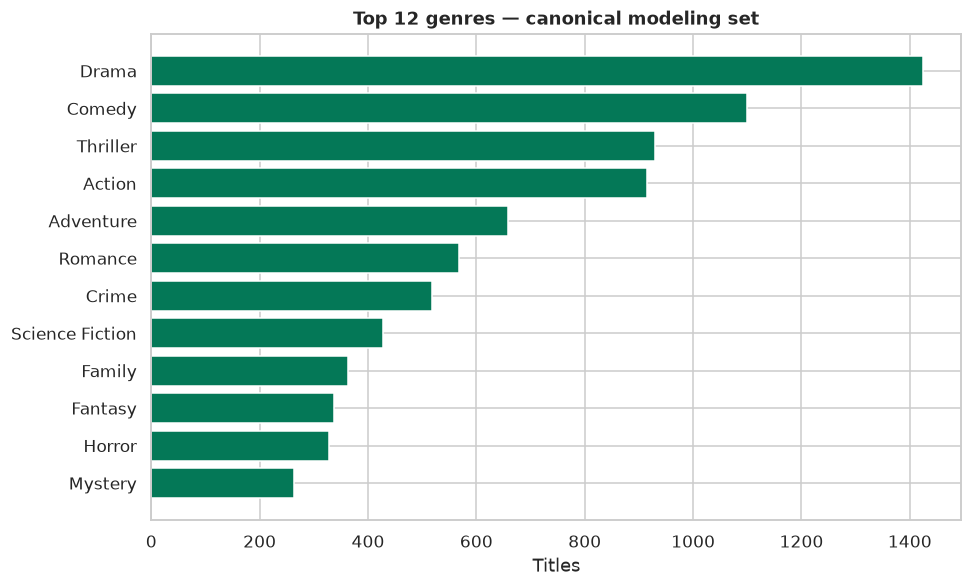

,titles
Drama,1424
Comedy,1099
Thriller,929
Action,914
Adventure,659
Romance,568
Crime,518
Science Fiction,427
Family,363
Fantasy,338


In [9]:
def parse_names(blob):
    try:
        return [entry['name'] for entry in json.loads(blob)]
    except (TypeError, ValueError):
        return []

genre_lists = df_model['genres'].apply(parse_names)
genre_counts = pd.Series([g for lst in genre_lists for g in lst]).value_counts()
print(f'Titles with empty genre lists in canonical set: {int((genre_lists.str.len() == 0).sum())}')
print(f'Distinct genre labels: {genre_counts.size}')

top_genres = genre_counts.head(12)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_genres.index, top_genres.values, color='#047857')
ax.set_title('Top 12 genres — canonical modeling set')
ax.set_xlabel('Titles')
plt.tight_layout(); plt.show()
genre_counts.head(12).to_frame('titles')

## 8. Correlation & the Leakage Prelude

The numeric block hides the dataset's most dangerous property: **post-release signals
co-mingle with pre-release ones**. `popularity`, `vote_average` and `vote_count` are computed
by TMDB *after* release (daily traffic, retrospective ratings) — they are unavailable to a
greenlighting executive and therefore constitute data leakage if used for prediction.

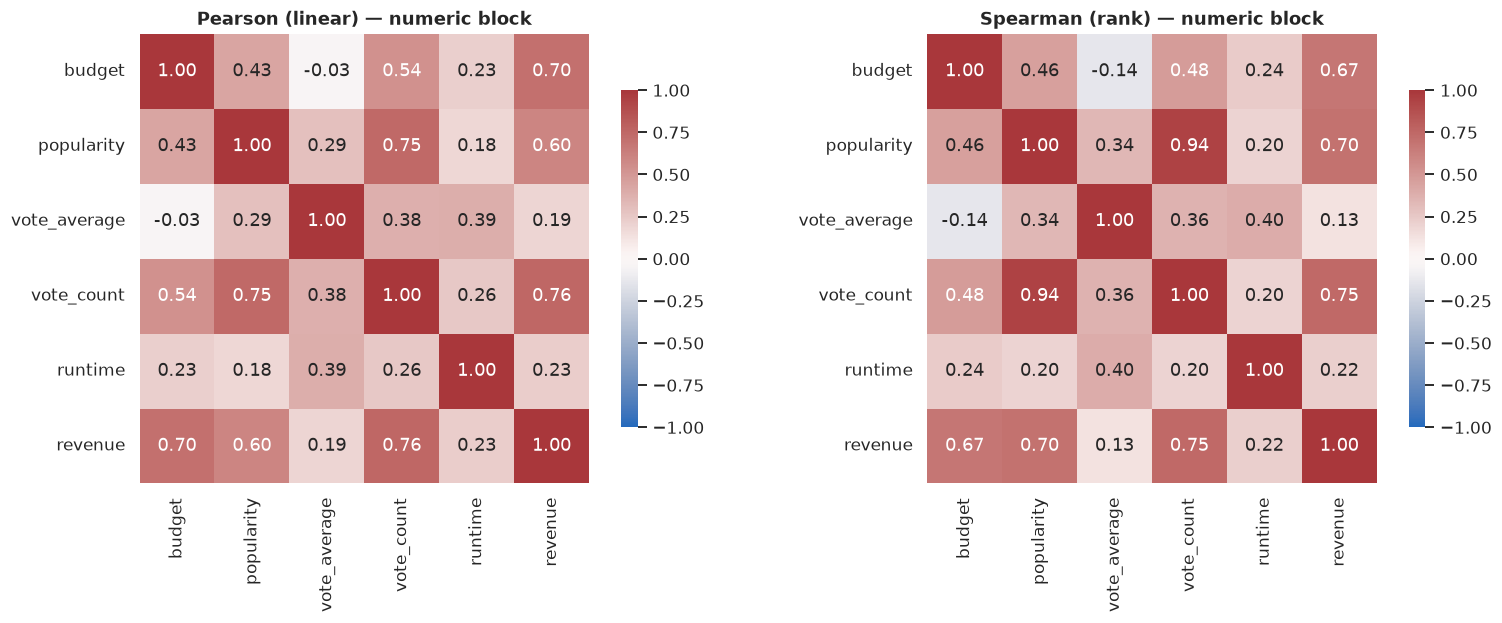

,Pearson ρ to revenue,Spearman ρ to revenue
vote_count,0.76,0.75
budget,0.70,0.67
popularity,0.60,0.70
runtime,0.23,0.22
vote_average,0.19,0.13


In [10]:
num_cols = ['budget', 'popularity', 'vote_average', 'vote_count', 'runtime', 'revenue']
pearson = df_model[num_cols].corr()
spearman = df_model[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
for ax, mat, method in zip(axes, [pearson, spearman], ['Pearson (linear)', 'Spearman (rank)']):
    sns.heatmap(mat, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
                square=True, cbar_kws={'shrink': .75}, ax=ax)
    ax.set_title(f'{method} — numeric block')
plt.tight_layout(); plt.show()

leakage_receipt = pd.DataFrame({'Pearson ρ to revenue': pearson['revenue'],
                                'Spearman ρ to revenue': spearman['revenue']}).drop(index='revenue')
leakage_receipt.sort_values('Pearson ρ to revenue', ascending=False)

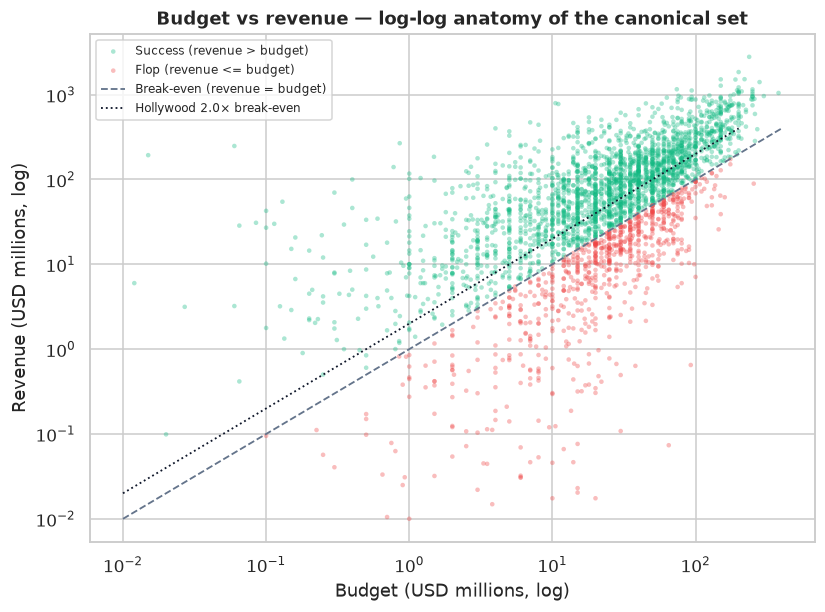

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 6))
for label, color, name in [(1, PALETTE['success'], 'Success (revenue > budget)'),
                           (0, PALETTE['flop'], 'Flop (revenue <= budget)')]:
    sub = df_model[df_model['target'] == label]
    ax.scatter(sub['budget'] / 1e6, sub['revenue'] / 1e6, s=9, alpha=.35, color=color,
               label=name, edgecolors='none')
ax.plot([0.01, 400], [0.01, 400], color='#64748b', lw=1.2, ls='--', label='Break-even (revenue = budget)')
ax.plot([0.01, 200], [0.02, 400], color='#0f172a', lw=1.2, ls=':', label='Hollywood 2.0× break-even')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Budget vs revenue — log-log anatomy of the canonical set')
ax.set_xlabel('Budget (USD millions, log)'); ax.set_ylabel('Revenue (USD millions, log)')
ax.legend(frameon=True, fontsize=8)
plt.show()

## 9. Seasonality & Temporal Structure

The theatrical calendar is a pre-release strategic variable: release month correlates with
gross potential (summer blockbusters, holiday corridors). Release counts alone mislead —
September is the busiest *dump* month, while revenue per title peaks in the summer and
holiday corridors.

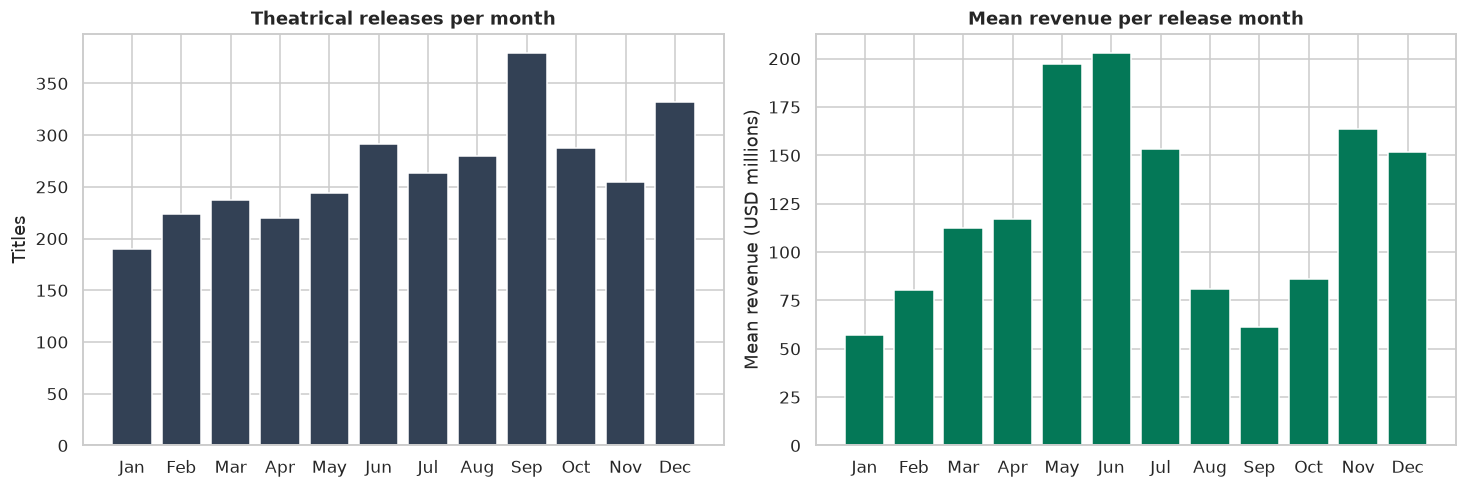

,releases,mean_revenue_M
Jan,190,57.02
Feb,224,80.27
Mar,237,112.55
Apr,220,117.16
May,244,197.20
Jun,291,202.71
Jul,263,153.39
Aug,280,80.69
Sep,379,61.39
Oct,288,86.21


In [12]:
temporal = df_model.copy()
temporal['release_month'] = pd.to_datetime(temporal['release_date'], errors='coerce').dt.month
monthly = temporal.groupby('release_month').agg(releases=('title', 'count'), mean_revenue=('revenue', 'mean'))
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly.index = month_names

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
axes[0].bar(monthly.index, monthly['releases'], color='#334155')
axes[0].set_title('Theatrical releases per month'); axes[0].set_ylabel('Titles')
axes[1].bar(monthly.index, monthly['mean_revenue'] / 1e6, color='#047857')
axes[1].set_title('Mean revenue per release month')
axes[1].set_ylabel('Mean revenue (USD millions)')
plt.tight_layout(); plt.show()

monthly_out = monthly.copy()
monthly_out['mean_revenue_M'] = monthly_out['mean_revenue'] / 1e6
monthly_out.drop(columns='mean_revenue')

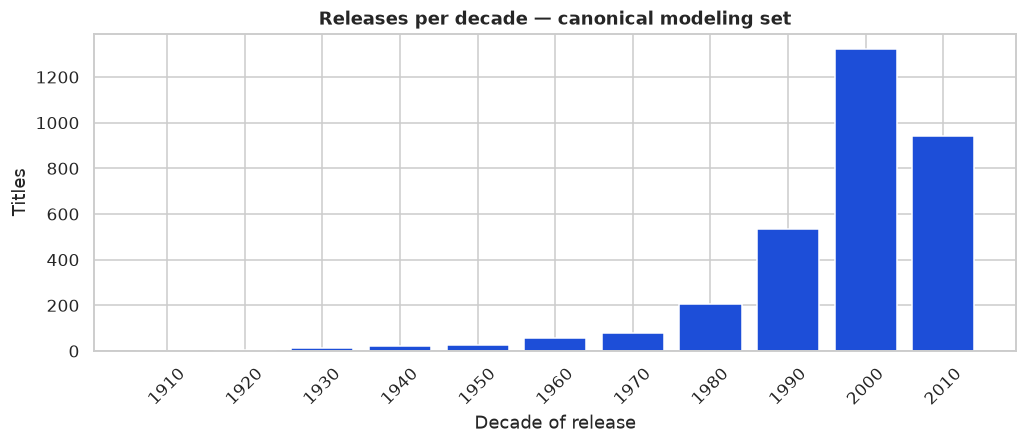

Release year range: 1916–2016


In [13]:
temporal['release_year'] = pd.to_datetime(temporal['release_date'], errors='coerce').dt.year
decade = (temporal['release_year'] // 10 * 10).astype('Int64')
decade_counts = decade.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(decade_counts.index.astype(str), decade_counts.values, color='#1d4ed8')
ax.set_title('Releases per decade — canonical modeling set')
ax.set_xlabel('Decade of release'); ax.set_ylabel('Titles')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()
print(f'Release year range: {int(temporal["release_year"].min())}–{int(temporal["release_year"].max())}')

## 10. Audit Summary & Canonical Handoff

The full selection funnel, receipts, and what the modeling notebooks inherit.

In [14]:
funnel = pd.DataFrame({
    'Stage': ['Raw Kaggle dump',
              'Stage 1 — theatrical filter (budget > 0 AND revenue > 0)',
              'Stage 2 — commercial-scale floor (budget > $10K AND revenue > $10K, strict)'],
    'Rule': ['—', 'Prune unrecorded financials', 'Prune currency-scale corruptions'],
    'Titles': [f'{len(df_raw):,}', f'{len(df_theatrical):,}', f'{len(df_model):,}'],
    'Removed': ['—', f'−{len(df_raw) - len(df_theatrical):,}', f'−{len(df_theatrical) - len(df_model)}'],
})
print(f'Selection funnel: {len(df_raw):,} → {len(df_theatrical):,} → {len(df_model):,}')
print()
print(funnel.to_string(index=False))
print()
print(f'Canonical modeling set: {len(df_model):,} titles × {df_model.shape[1]} columns '
      '(22 features + didactic & Hollywood targets)')

Selection funnel: 4,803 → 3,229 → 3,203

                                                                      Stage                             Rule Titles Removed
                                                            Raw Kaggle dump                                —  4,803       —
                   Stage 1 — theatrical filter (budget > 0 AND revenue > 0)      Prune unrecorded financials  3,229  −1,574
Stage 2 — commercial-scale floor (budget > $10K AND revenue > $10K, strict) Prune currency-scale corruptions  3,203     −26

Canonical modeling set: 3,203 titles × 24 columns (22 features + didactic & Hollywood targets)


### Key findings carried forward

* **Selection funnel:** 4,803 raw → **3,229** theatrically reported → **3,203** canonical
  modeling titles; 26 currency-corrupted entries isolated and pruned (strict > $10K floor).
* **Survivorship trap:** ~75.8% of canonical titles beat their nominal budget — a
  majority-class dummy is already ~75.8% accurate. Accuracy is a vanity metric here;
  **Balanced Accuracy, Macro F1, ROC-AUC and portfolio ROI** are the evaluation spine.
* **Realistic economics:** at the Hollywood 2.0× break-even the classes are nearly balanced
  (~56/44) — the modeling stages evaluate both target definitions.
* **Pareto concentration:** the top 20% of titles capture ~two-thirds of all gross;
  `log1p` transforms are mandatory for the linear model.
* **Leakage quarantine list:** `popularity` (ρ ≈ 0.60 with revenue), `vote_average`,
  `vote_count` are post-release — excluded from the pre-release feature store and used
  only in the controlled leakage experiment (notebook 04).
* **Pre-release feature candidates handed to V1:** log-budget, multi-hot genres, runtime,
  release month/year, original language, plus the synopsis/cast/crew blocks for V2.

**Next:** [`02_baseline_linear_model.ipynb`](./02_baseline_linear_model.ipynb) — regularized
logistic baseline vs. the majority-class dummy on the canonical set.